# HDD 고장 예측 EDA v3 — Seagate 10종 · SMART 20개

| 항목 | 내용 |
|---|---|
| 목표 | 향후 **30일 안에 고장 날 디스크**를 찾는다 |
| 분석 대상 | 고장 디스크 수 상위 20종 중 **Seagate 10종** |
| 전체 HDD 대비 | 디스크 **29.95%**, 고장 디스크 **38.66%** |
| 입력 후보 | 10종이 모두 기록한 SMART raw **20개** (v2의 공통 13개가 아님) |
| 기간 | 2024-04-01~2026-06-30, **821일 전체** |
| 비교 방식 | 매월 1일을 예측 시점으로 잡고, 같은 모델·같은 날짜의 고장 예정 디스크와 정상 디스크를 비교 |
| 미수행 | 머신러닝 학습·성능 평가 |

## 1. 분석 목적

| 질문 | 이 답으로 정할 것 |
|---|---|
| Q1. 어떤 컬럼이 고장 예정 디스크와 정상 디스크를 구분하는가? | 핵심 컬럼 |
| Q2. 고장 신호는 언제부터 나타나고, 현재 값과 변화량 중 무엇이 나은가? | 입력 방식 |
| Q3. 손상 지표가 0인 채 고장 나는 디스크는 얼마나 되는가? | 한계와 보완 컬럼 |
| Q4. 단순 규칙(손상 지표 > 0)의 경보 성능은? | 모델이 넘어야 할 기준선 |

In [1]:
from pathlib import Path
import json
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'Malgun Gothic','axes.unicode_minus':False,'figure.dpi':110})
pd.set_option('display.width',200); pd.set_option('display.max_columns',30)
cwd=Path.cwd().resolve()
ROOT=next(p for p in (cwd,cwd.parent) if (p/'eda/analysis/v3/analysis_manifest.json').exists())
EDA=ROOT/'eda'; OUT=EDA/'analysis/v3'; FIG=EDA/'figures/eda_v3'; FIG.mkdir(parents=True,exist_ok=True)
DATA=ROOT/'data/backblaze/seagate10/seagate10_2024Q2-2026Q2.parquet'
read=lambda n:pd.read_csv(OUT/f'{n}.csv')
cols=json.loads((OUT/'selected_columns.json').read_text())
def save(name):
    plt.tight_layout(); plt.savefig(FIG/f'{name}.png',bbox_inches='tight'); plt.show()

## 2. 데이터셋 설명

### 2-1. 출처·범위

[Backblaze Drive Stats](https://www.backblaze.com/cloud-storage/resources/hard-drive-test-data)의 1행은 디스크 1개의 하루 기록이다. 고장 수 상위 20종 중 Seagate 10종을 골랐다. v1은 이 중 `ST12000NM0008` 1종이었다.

전체 HDD 75종(SSD 21종·DELLBOSS VD 제외)과 같은 기간을 비교하면, Seagate 10종은 **디스크 29.95%**, **고장 디스크 38.66%**를 포함한다.

| 대상 | 디스크 수 | 전체 HDD 대비 | 고장 디스크 수 | 전체 고장 HDD 대비 |
|---|---:|---:|---:|---:|
| Seagate 10종 (v3) | 115,901 | 29.95% | 4,066 | 38.66% |
| HDD 75종 전체 | 386,919 | 100.00% | 10,518 | 100.00% |

파일명의 **30%는 전체 HDD 디스크 수 대비 비중을 반올림한 값**이다. 샘플링 비율이 아니며, 고장 비중은 시리얼별로 고장 디스크를 한 번만 센 값이다. 연간 고장률이나 30일 고장 라벨의 양성 비율과 다르다.

근거: [모델별 원본 집계](../data/backblaze/summary/model_rank.csv), [v3 범위 집계](../data/backblaze/summary/eda_v3_scope.csv). 원자료: [Backblaze Drive Stats](https://www.backblaze.com/cloud-storage/resources/hard-drive-test-data).


In [2]:
m=pd.read_csv(OUT/'selected_models.csv')
display(m.rename(columns={'model':'모델','disks':'디스크 수','failed_disks':'고장 디스크 수','failures':'고장 기록','drive_days':'가동일 합','관측기간_고장비율_pct':'고장 비율(%)'}))

,모델,디스크 수,고장 디스크 수,고장 기록,가동일 합,고장 비율(%)
0,ST12000NM0008,19516,1117,1118,15506879,5.72
1,ST8000NM0055,13838,717,719,10983313,5.18
2,ST16000NM001G,35527,459,459,27800550,1.29
3,ST8000DM002,9230,345,345,6995241,3.74
4,ST14000NM001G,10807,335,336,8670727,3.10
5,ST12000NM001G,13475,328,328,10821706,2.43
6,ST24000NM002H,9900,302,302,3640687,3.05
7,ST12000NM0007,1131,163,164,838428,14.41
8,ST14000NM0138,1380,162,162,1061036,11.74
9,ST10000NM0086,1097,138,139,831940,12.58


### 2-2. 컬럼 설명 — 기본 정보 6개 + SMART 20개

SMART는 **10종이 모두 기록한 raw 값**만 골랐다. 일부 모델만 기록한 컬럼은 입력에서 뺐다(200번 8종, 18·195번 6종, 184·189·191번 3종).

| # | 컬럼 | 설명 | 단위 |
|---:|---|---|---|
| 1 | `date` | 관측 날짜 | 년-월-일 |
| 2 | `serial_number` | 디스크 고유 식별자 | 해당 없음 |
| 3 | `model` | HDD 제품명 | 해당 없음 |
| 4 | `capacity_bytes` | 디스크 용량 | byte |
| 5 | `failure` | 그날 고장 났는지 표시. 30일 안에 고장 날지 맞히는 정답을 만들 때 쓴다 | 0/1 |
| 6 | `datacenter` | 디스크가 있는 데이터센터 코드 | 해당 없음 |
| 7 | `smart_1_raw` | 읽기 오류와 관련된 값 | 제조사별로 다름 |
| 8 | `smart_3_raw` | 디스크가 회전을 시작하는 동작과 관련된 값 | 제조사별로 다름 |
| 9 | `smart_4_raw` | 디스크가 시작·정지한 횟수 | 회 |
| 10 | **`smart_5_raw`** | 재할당 섹터 수. 디스크가 고친 불량 칸의 개수 | 개 |
| 11 | `smart_7_raw` | 헤드가 원하는 위치를 찾는 동작과 관련된 값 | 제조사별로 다름 |
| 12 | `smart_9_raw` | 누적 가동시간. 디스크가 켜져 있던 총 시간 | 시간(h) |
| 13 | `smart_10_raw` | 디스크 회전을 다시 시도한 것과 관련된 값 | 제조사별로 다름 |
| 14 | `smart_12_raw` | 전원이 켜진 횟수 | 회 |
| 15 | **`smart_187_raw`** | 보고된 복구 불가 오류 수. 읽기를 시도했지만 끝내 복구하지 못한 오류 횟수 | 회 |
| 16 | `smart_188_raw` | 명령 시간 초과. 디스크가 명령에 제때 응답하지 못한 것과 관련된 값 | 제조사별로 다름 |
| 17 | `smart_190_raw` | 공기 흐름 온도 | ℃ |
| 18 | `smart_192_raw` | 갑자기 전원이 꺼져 헤드를 급히 치운 것과 관련된 횟수 | 회 |
| 19 | `smart_193_raw` | 헤드를 올리고 내린 횟수 | 회 |
| 20 | `smart_194_raw` | 관측일에 디스크 센서로 잰 온도(순간 값) | ℃ |
| 21 | **`smart_197_raw`** | 보류 중인 섹터 수. 불량이 의심돼 확인을 기다리는 칸의 개수 | 개 |
| 22 | **`smart_198_raw`** | 오프라인 복구 불가 섹터 수. 검사했더니 못 고친 불량 칸의 개수 | 개 |
| 23 | `smart_199_raw` | 디스크와 연결선 사이 데이터 전송 오류(CRC) 횟수 | 회 |
| 24 | `smart_240_raw` | 헤드가 움직인 시간과 관련된 값 | 제조사별로 다름 |
| 25 | `smart_241_raw` | 호스트(서버)가 디스크에 기록한 논리 블록 수 | 개(블록) |
| 26 | `smart_242_raw` | 호스트(서버)가 디스크에서 읽은 논리 블록 수 | 개(블록) |

## 3. 전처리·데이터 품질

### 3-1. 첫 고장 정제

디스크마다 **첫 고장일까지의 기록만** 쓴다. 고장 후 재투입된 기록은 버린다.

In [3]:
c=read('cohort').iloc[0]; s=read('clean_scale').iloc[0]
display(Markdown(f"""
| 항목 | 값 |
|---|---:|
| 디스크 수 | {int(c.disks):,}개 |
| 고장 디스크 수(첫 고장 기준) | {int(c.failed_disks):,}개 |
| 고장이 두 번 이상 기록된 디스크 | {int(c.repeated_failure_disks):,}개 |
| 고장 후에도 기록이 남은 디스크 | {int(c.post_failure_disks):,}개 |
| 원본 행 → 정제 후 행 | {int(s.raw_rows):,} → {int(s.clean_rows):,} |
"""))


| 항목 | 값 |
|---|---:|
| 디스크 수 | 115,901개 |
| 고장 디스크 수(첫 고장 기준) | 4,066개 |
| 고장이 두 번 이상 기록된 디스크 | 6개 |
| 고장 후에도 기록이 남은 디스크 | 61개 |
| 원본 행 → 정제 후 행 | 87,150,507 → 87,132,092 |


### 3-2. 0이 많은 컬럼

손상 지표(5·187·197·198)는 **0이 정상**이다. 문제는 고장 디스크도 0인 경우다(4-4절). 3·10번은 값이 변하지 않는 상수다.

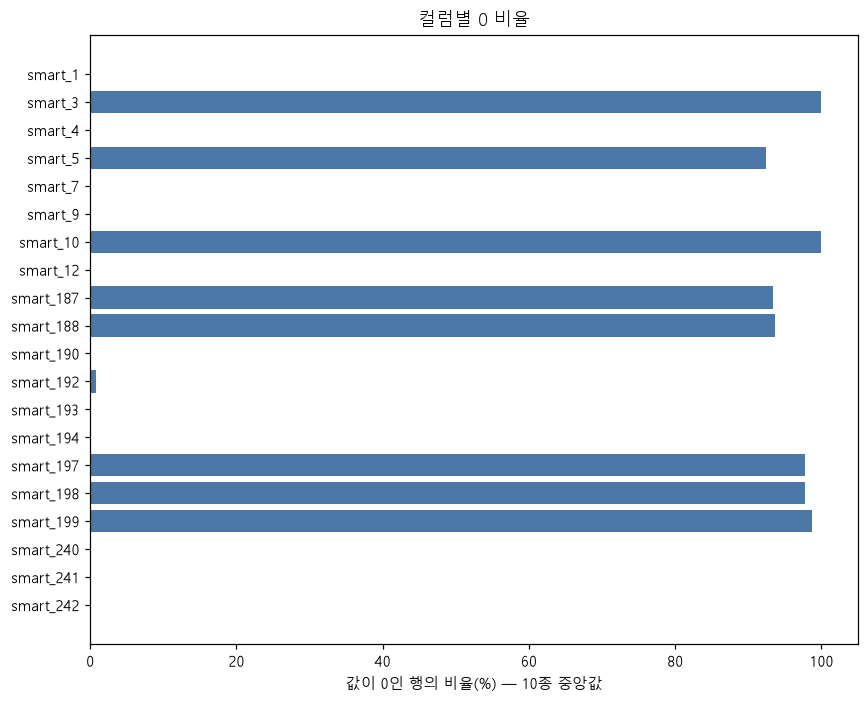

,컬럼,0 비율(%) 중앙값,결측 최대(%),상수인_모델수
11,smart_1_raw,0.00,0.07,0.0
15,smart_3_raw,100.00,0.07,10.0
16,smart_4_raw,0.00,0.07,0.0
17,smart_5_raw,92.44,0.07,0.0
18,smart_7_raw,0.00,0.07,0.0
19,smart_9_raw,0.00,0.07,0.0
0,smart_10_raw,100.00,0.07,10.0
1,smart_12_raw,0.00,0.07,0.0
2,smart_187_raw,93.35,0.07,0.0
3,smart_188_raw,93.68,0.07,0.0


In [4]:
q=read('value_quality_by_model')
z=q.groupby('column').agg(zero=('zero_pct','median'),miss=('missing_pct','max'),const=('min',lambda x:0)).reset_index()
const=q[q['min']==q['max']].groupby('column').size().rename('상수인_모델수')
z=z.drop(columns='const').merge(const,on='column',how='left').fillna({'상수인_모델수':0})
z['n']=z.column.str.extract(r'(\d+)').astype(int); z=z.sort_values('n')
fig,ax=plt.subplots(figsize=(8,6.5))
ax.barh(z.column.str.replace('_raw',''),z.zero,color='#4C78A8'); ax.invert_yaxis()
ax.set_xlabel('값이 0인 행의 비율(%) — 10종 중앙값'); ax.set_title('컬럼별 0 비율')
save('3-2_zero_rates')
display(z.rename(columns={'column':'컬럼','zero':'0 비율(%) 중앙값','miss':'결측 최대(%)'})[['컬럼','0 비율(%) 중앙값','결측 최대(%)','상수인_모델수']].round(2))

### 3-3. 30일 라벨

매월 1일을 예측 시점 t로 잡는다. **0 < 첫 고장일 − t ≤ 30일이면 양성**이다. 관측이 끝나 30일 뒤를 알 수 없는 정상 디스크는 뺀다.

In [5]:
l=read('label_summary').iloc[0]
display(Markdown(f"월별 예측 시점 **{int(l.dates)}개**, 디스크-월 표본 **{int(l.snapshots):,}개**, 양성 **{int(l.positive_snapshots):,}개**({l.positive_pct:.2f}%)"))

월별 예측 시점 **26개**, 디스크-월 표본 **2,750,394개**, 양성 **3,536개**(0.13%)

## 4. 데이터 시각화·상세 분석

### 4-1. 모델별 규모·고장률

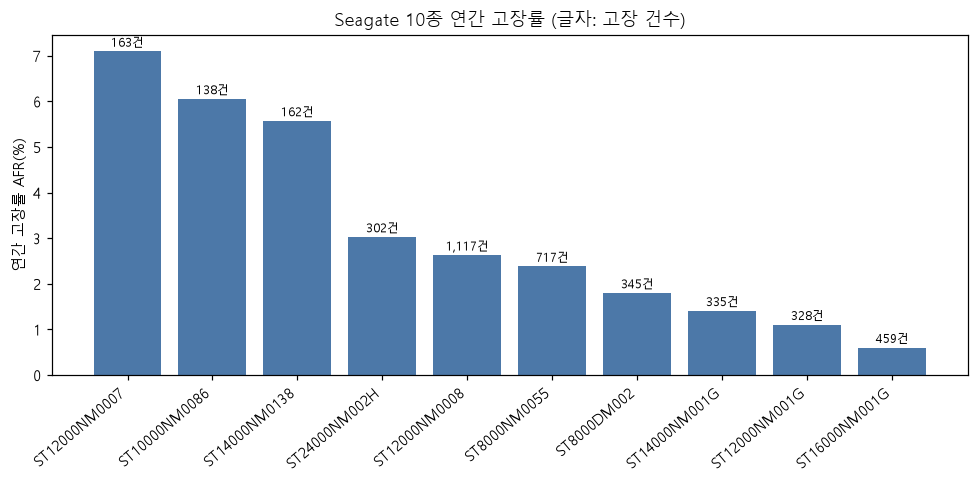

,모델,가동일 합,고장 수,디스크 수,AFR(%)
2,ST12000NM0007,838406,163.0,1131,7.10
1,ST10000NM0086,831935,138.0,1097,6.06
9,ST14000NM0138,1061030,162.0,1380,5.57
5,ST24000NM002H,3640687,302.0,9900,3.03
3,ST12000NM0008,15505160,1117.0,19516,2.63
7,ST8000NM0055,10983293,717.0,13838,2.38
0,ST8000DM002,6995233,345.0,9230,1.80
4,ST14000NM001G,8670707,335.0,10807,1.41
8,ST12000NM001G,10821706,328.0,13475,1.11
6,ST16000NM001G,27783935,459.0,35527,0.60


In [6]:
ms=read('model_scale').sort_values('afr_pct',ascending=False)
fig,ax=plt.subplots(figsize=(9,4.5))
ax.bar(ms.model,ms.afr_pct,color='#4C78A8')
for i,(a,f) in enumerate(zip(ms.afr_pct,ms.failures)):ax.text(i,a+.1,f'{int(f):,}건',ha='center',fontsize=8)
ax.set_ylabel('연간 고장률 AFR(%)'); ax.set_title('Seagate 10종 연간 고장률 (글자: 고장 건수)'); plt.xticks(rotation=40,ha='right')
save('4-1_model_afr')
display(ms.rename(columns={'model':'모델','drive_days':'가동일 합','failures':'고장 수','disks':'디스크 수','afr_pct':'AFR(%)'}).round(2))

### 4-2. 고장 예정 vs 정상 — 모델 안에서 비교 (Q1)

모델별 **rank-biserial 상관**이다. 같은 모델·같은 날짜의 고장 예정 디스크와 정상 디스크를 비교한다(정상은 양성 1개당 최대 5개). 양수면 고장 예정 디스크의 값이 더 크다는 뜻이고, 0이면 구분되지 않는다.

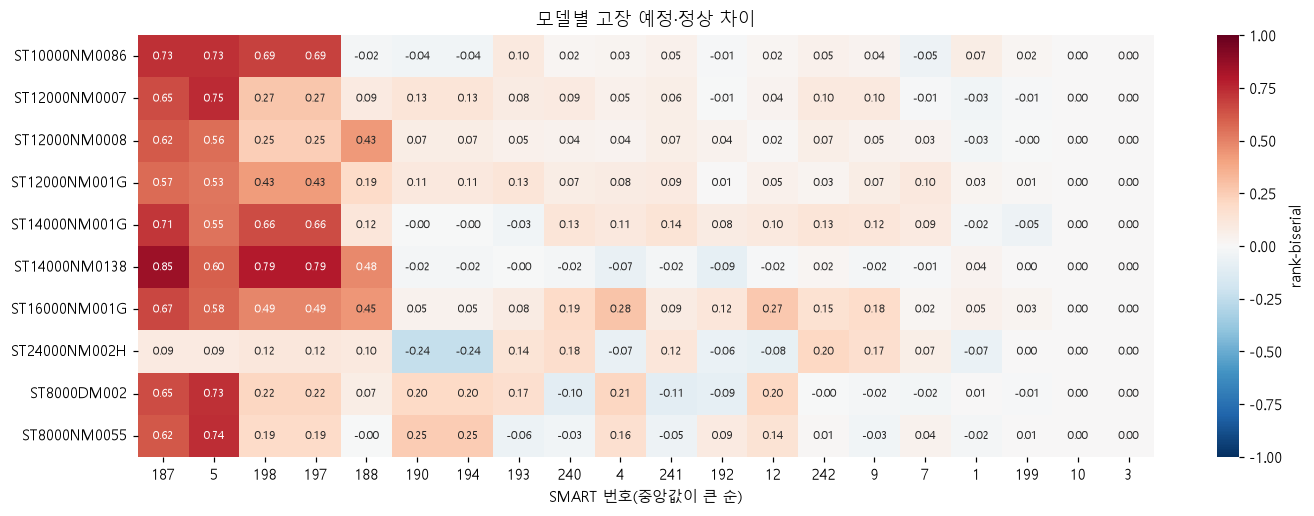

,컬럼,중앙값,양수_모델수,음수_모델수
0,smart_187_raw,0.652,10,0
1,smart_5_raw,0.589,10,0
2,smart_198_raw,0.352,10,0
3,smart_197_raw,0.352,10,0
4,smart_188_raw,0.109,8,2
5,smart_190_raw,0.091,6,4
6,smart_194_raw,0.091,6,4
7,smart_193_raw,0.083,7,3
8,smart_240_raw,0.081,7,3
9,smart_4_raw,0.079,8,2


In [7]:
e=read('effects_by_model'); cur=e[e.feature.isin(cols)]
hm=cur.pivot(index='model',columns='feature',values='rank_biserial')
order=cur.assign(a=cur.rank_biserial.abs()).groupby('feature').a.median().sort_values(ascending=False).index.tolist()
hm=hm[order]; hm.columns=[c.replace('smart_','').replace('_raw','') for c in hm.columns]
fig,ax=plt.subplots(figsize=(13,4.8))
sns.heatmap(hm,annot=True,fmt='.2f',cmap='RdBu_r',center=0,vmin=-1,vmax=1,ax=ax,annot_kws={'fontsize':7},cbar_kws={'label':'rank-biserial'})
ax.set_xlabel('SMART 번호(중앙값이 큰 순)'); ax.set_ylabel(''); ax.set_title('모델별 고장 예정·정상 차이')
save('4-2_model_effects')
rk=cur.assign(a=cur.rank_biserial.abs()).groupby('feature').agg(중앙값=('a','median'),양수_모델수=('rank_biserial',lambda x:int((x>0).sum())),음수_모델수=('rank_biserial',lambda x:int((x<0).sum()))).loc[order].reset_index().rename(columns={'feature':'컬럼'})
display(rk.round(3))

### 4-3. 같은 값을 가진 컬럼 (Q1 보충)

값이 모든 행에서 똑같은 컬럼 쌍은 하나만 입력으로 쓴다.

In [8]:
con=duckdb.connect()
dup=con.sql(f"""SELECT model,count(*) AS 행수,
  count(*) FILTER(WHERE smart_197_raw IS DISTINCT FROM smart_198_raw) AS "197과 198이 다른 행",
  count(*) FILTER(WHERE smart_190_raw IS DISTINCT FROM smart_194_raw) AS "190과 194가 다른 행",
  count(*) FILTER(WHERE smart_4_raw IS DISTINCT FROM smart_12_raw) AS "4와 12가 다른 행"
  FROM read_parquet('{DATA.as_posix()}') GROUP BY model ORDER BY model""").df()
display(dup)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,model,행수,197과 198이 다른 행,190과 194가 다른 행,4와 12가 다른 행
0,ST10000NM0086,831940,0,0,804510
1,ST12000NM0007,838428,0,0,87327
2,ST12000NM0008,15506879,0,0,3486942
3,ST12000NM001G,10821706,0,0,1559220
4,ST14000NM001G,8670727,0,0,581105
5,ST14000NM0138,1061036,0,0,1055926
6,ST16000NM001G,27800550,0,0,2493303
7,ST24000NM002H,3640687,0,0,663554
8,ST8000DM002,6995241,0,0,1064160
9,ST8000NM0055,10983313,0,0,1826840


In [9]:
display(Markdown(f"**197·198**은 10종 모두에서 다른 행이 **{int(dup['197과 198이 다른 행'].sum())}개**, **190·194**는 **{int(dup['190과 194가 다른 행'].sum())}개**다. 완전히 같은 값이므로 각각 하나만 쓴다. 4번과 12번은 다른 행이 많아서 서로 다른 값이다."))

**197·198**은 10종 모두에서 다른 행이 **0개**, **190·194**는 **0개**다. 완전히 같은 값이므로 각각 하나만 쓴다. 4번과 12번은 다른 행이 많아서 서로 다른 값이다.

### 4-4. 고장 전 궤적 (Q2·Q3)

고장 난 디스크가 **고장 N일 전에 손상 지표 > 0이었던 비율**이다(10종 합산).

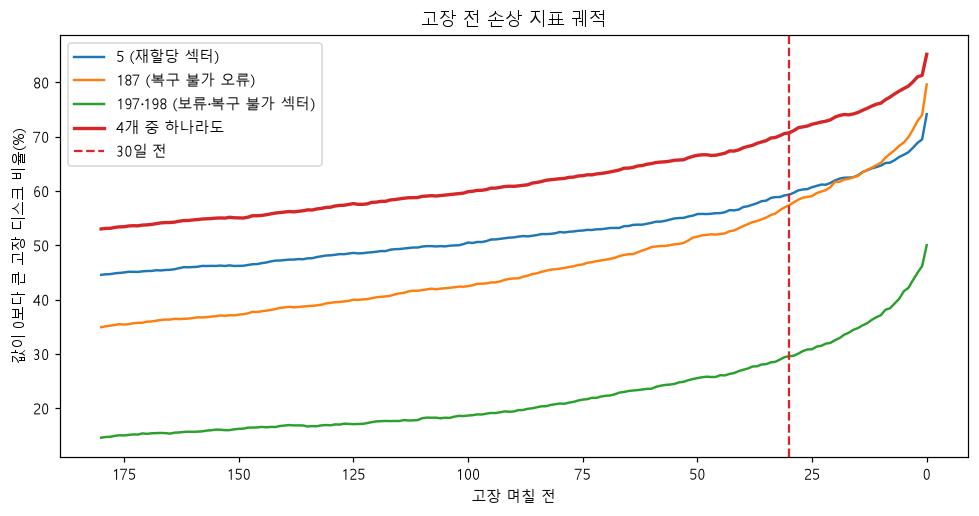

- 고장 디스크 중 손상 지표(5·187·197·198)가 **관측 기간 내내 0**이었던 비율: **15.4%**
- 손상 신호가 처음 나타난 날부터 고장까지 일수의 **중앙값**: **151일** (신호가 있었던 디스크 기준)

In [10]:
t=read('trajectories')
cols_t={'reallocated_gt0_pct':'5 (재할당 섹터)','uncorrectable_gt0_pct':'187 (복구 불가 오류)','pending_gt0_pct':'197·198 (보류·복구 불가 섹터)','any_damage_gt0_pct':'4개 중 하나라도'}
fig,ax=plt.subplots(figsize=(9,4.8))
for k,lab in cols_t.items():
    g=t.groupby('days_before').apply(lambda d:(d[k]*d.observed_disks).sum()/d.observed_disks.sum())
    ax.plot(g.index,g.values,label=lab,lw=2.2 if k=='any_damage_gt0_pct' else 1.6)
ax.axvline(30,color='#D62728',linestyle='--',linewidth=1.5,label='30일 전')
ax.invert_xaxis(); ax.set_xlabel('고장 며칠 전'); ax.set_ylabel('값이 0보다 큰 고장 디스크 비율(%)'); ax.set_title('고장 전 손상 지표 궤적'); ax.legend()
save('4-4_trajectories')
lt=read('lead_times'); none=lt.first_signal.isna().mean()*100
display(Markdown(f"""- 고장 디스크 중 손상 지표(5·187·197·198)가 **관측 기간 내내 0**이었던 비율: **{none:.1f}%**
- 손상 신호가 처음 나타난 날부터 고장까지 일수의 **중앙값**: **{lt.lead_days.median():.0f}일** (신호가 있었던 디스크 기준)"""))

### 4-5. 현재 값과 변화량 (Q2)

7·30·90일 전과 비교한 증가량이 현재 값보다 나은지 본다. 5번과 187번 기준이다.

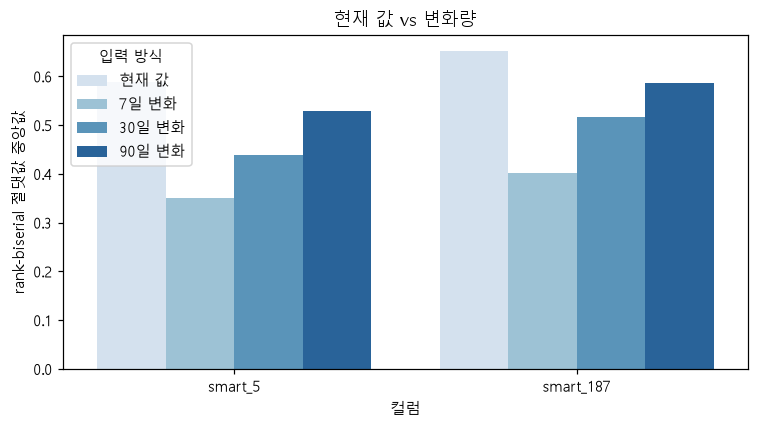

입력 방식,현재 값,7일 변화,30일 변화,90일 변화
컬럼,,,,
smart_187,0.652,0.401,0.516,0.586
smart_5,0.589,0.349,0.438,0.528


In [11]:
rows=[]
for base in ('smart_5_raw','smart_187_raw'):
    for lab,f in (('현재 값',base),('7일 변화',f'delta_{base}_7'),('30일 변화',f'delta_{base}_30'),('90일 변화',f'delta_{base}_90')):
        r=e[e.feature==f].rank_biserial.abs().median(); rows.append({'컬럼':base.replace('_raw',''),'입력 방식':lab,'중앙값':r})
cd=pd.DataFrame(rows)
fig,ax=plt.subplots(figsize=(7,4))
sns.barplot(data=cd,x='컬럼',y='중앙값',hue='입력 방식',ax=ax,palette='Blues')
ax.set_ylabel('rank-biserial 절댓값 중앙값'); ax.set_title('현재 값 vs 변화량')
save('4-5_current_vs_delta')
display(cd.pivot(index='컬럼',columns='입력 방식',values='중앙값')[['현재 값','7일 변화','30일 변화','90일 변화']].round(3))

### 4-6. 단순 규칙 기준선 (Q4)

같은 월별 평가 집단에서 규칙을 비교한다. 재현율은 고장 예정 디스크 중 경보가 울린 비율, 정밀도는 경보 중 실제 고장 예정인 비율이다.

In [12]:
rb=read('rule_baselines')
display(rb[['rule','alerts','tp','recall_pct','precision_pct','monthly_alerts']].rename(columns={'rule':'규칙','alerts':'경보 수','tp':'적중','recall_pct':'재현율(%)','precision_pct':'정밀도(%)','monthly_alerts':'월 평균 경보'}).round(1))

,규칙,경보 수,적중,재현율(%),정밀도(%),월 평균 경보
0,손상 지표 4개 중 하나라도 > 0,250093.0,2512.0,75.6,1.0,10003.7
1,재할당 섹터(5) > 0,205453.0,2118.0,63.8,1.0,8218.1
2,복구 불가 섹터(198) > 0,34979.0,1189.0,35.8,3.4,1399.2
3,손상 신호 + 최근 30일 증가,47832.0,2098.0,63.2,4.4,1913.3


## 5. 인사이트 → 모델링 반영

In [13]:
a=rk.set_index('컬럼')['중앙값']
n_pos=lambda c:int(rk.set_index('컬럼').loc[c,'양수_모델수'])
r0=rb.iloc[0]
display(Markdown(f"""
### 5-1. 결과 요약

- **고장과 가장 잘 구분되는 컬럼은 187번({a['smart_187_raw']:.3f})과 5번({a['smart_5_raw']:.3f})**이고, 둘 다 10종 모두에서 고장 예정 디스크의 값이 더 컸다. 198·197번은 {a['smart_198_raw']:.3f}이다.
- 197번과 198번은 값이 완전히 같다. 190번과 194번도 같다.
- 3번과 10번은 값이 변하지 않아 구분 능력이 없다(점수 0).
- 5번과 187번에서는 변화량(7·30·90일)보다 현재 값의 점수가 더 높았다. 두 방식을 함께 검증한다.
- 고장 디스크의 **{none:.1f}%**는 손상 지표가 끝까지 0이었다. 갑자기 고장 나는 경우는 이 컬럼들로 잡을 수 없다.
- 손상 지표 중 하나라도 0보다 크다는 규칙은 재현율 {r0.recall_pct:.1f}%, 정밀도 {r0.precision_pct:.1f}%다. 경보 대부분이 헛경보라서, 모델은 이 정밀도를 넘어야 한다.
"""))


### 5-1. 결과 요약

- **고장과 가장 잘 구분되는 컬럼은 187번(0.652)과 5번(0.589)**이고, 둘 다 10종 모두에서 고장 예정 디스크의 값이 더 컸다. 198·197번은 0.352이다.
- 197번과 198번은 값이 완전히 같다. 190번과 194번도 같다.
- 3번과 10번은 값이 변하지 않아 구분 능력이 없다(점수 0).
- 5번과 187번에서는 변화량(7·30·90일)보다 현재 값의 점수가 더 높았다. 두 방식을 함께 검증한다.
- 고장 디스크의 **15.4%**는 손상 지표가 끝까지 0이었다. 갑자기 고장 나는 경우는 이 컬럼들로 잡을 수 없다.
- 손상 지표 중 하나라도 0보다 크다는 규칙은 재현율 75.6%, 정밀도 1.0%다. 경보 대부분이 헛경보라서, 모델은 이 정밀도를 넘어야 한다.


### 5-2. 컬럼 후보 (초안)

| 구분 | 컬럼 |
|---|---|
| 우선 검증 | 5, 187, 198(=197) |
| 함께 검증 | 4, 9, 12, 193, 194(=190), 199, 188, 192, 240, 241, 242 |
| 제외 후보 | 3, 10(상수), 1, 7(값 해석이 제조사별로 다르고 구분 능력이 낮음), 197(198과 같은 값), 190(194와 같은 값) |

학습 성능으로 정한 최종 목록이 아니라 EDA 기준의 초안이다.

### 5-3. 적용 범위·한계

- 이 결과는 **Seagate 10종**의 EDA다. 다른 제조사와 나머지 모델에는 그대로 적용하지 않는다.
- 20종 선정에 전체 기간의 고장 수를 썼다. 최종 평가에서는 미래 고장 수를 보지 않고 학습 기간에서 대상을 정하는 절차를 검토한다.
- 월별 평가라 매일 경고하는 운영 시스템과 다르다. 규칙 결과는 미래 테스트 성능이 아니다.
- 원본에 고장 원인과 펌웨어 버전이 없다. 관측이 끝날 때까지 고장 나지 않은 디스크의 수명은 알 수 없다.
- 다음 단계는 30일 라벨을 유지하고 현재 값·변화량으로 모델을 학습하는 것이다.

### 재현 경로

1. `scripts/18_extract_seagate10.py`: 원본 821일에서 Seagate 10종·SMART 20개 추출 (`HDD_RAW_DIR` 필요)
2. `scripts/19_analyze_seagate10.py`: 첫 고장 정제·월별 라벨·매칭 비교·궤적·규칙 계산
3. `scripts/20_build_eda_v3.py`: 이 노트북 생성·실행